# 形態素解析とサブワード分割（分割単位・正規化・未知語処理・Subword Regularization）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch3_morphology_ner.ipynb)

書籍 第3章「系列ラベリング問題の解き方」（3-2 形態素解析：単語分割の基準・サブワード化、関連論文 3章 6）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、以下の内容を体験します。

1. `SudachiPy` による形態素解析と分割単位 (Mode A / B / C) の違い、品詞・見出し語化・正規化形（3-2「単語分割の基準」）
2. 未知語・新語に対する辞書ベース形態素解析 (`SudachiPy`) の振る舞いと `SentencePiece` によるサブワード分割の比較（3-2「サブワード化」）
3. ユニグラム言語モデルによる複数サブワード分割候補と Subword Regularization（3-2・関連論文 3章 6）

## 1. 準備

形態素解析器 `SudachiPy`（辞書 `sudachidict_core`）およびサブワード分割器 `SentencePiece` をインストールします。

In [1]:
!pip install -q sudachipy sudachidict_core sentencepiece

In [2]:
import tempfile
from pathlib import Path

import pandas as pd
import sentencepiece as spm
from IPython.display import display
from sudachipy import dictionary, tokenizer

---

## 2. 形態素解析と分割単位（3-2「単語分割の基準」）

日本語は英語と異なり単語の境界が空白で区切られていないため、タスクや目的に応じて「どこまでを 1 単語とするか（分割単位）」を決める必要があります。
`SudachiPy` では、1 つの辞書で以下の 3 つの分割モードを切り替えられます。

- **Mode A（短単位相当）**: 最も細かい分割（検索や詳細な言語学的分析向け）
- **Mode B（中単位相当）**: 複合語の一部をまとめた中間的な分割
- **Mode C（長単位相当）**: 固有名詞や複合語をひとまとまりとして扱う分割（固有表現認識や情報抽出向け）

In [3]:
sudachi = dictionary.Dictionary().create()

sample_texts = [
    "東京都立大学で自然言語処理を学ぶ。",
    "関西国際空港から新型コロナウイルス感染症の対策会議へ向かう。",
]

mode_map = {
    "Mode A（短単位）": tokenizer.Tokenizer.SplitMode.A,
    "Mode B（中単位）": tokenizer.Tokenizer.SplitMode.B,
    "Mode C（長単位）": tokenizer.Tokenizer.SplitMode.C,
}

for text in sample_texts:
    print(f"入力文: {text}")
    for name, mode in mode_map.items():
        tokens = [m.surface() for m in sudachi.tokenize(text, mode)]
        print(f"  {name}: {' / '.join(tokens)}")
    print()

入力文: 東京都立大学で自然言語処理を学ぶ。
  Mode A（短単位）: 東京 / 都立 / 大学 / で / 自然 / 言語 / 処理 / を / 学ぶ / 。
  Mode B（中単位）: 東京 / 都立 / 大学 / で / 自然 / 言語 / 処理 / を / 学ぶ / 。
  Mode C（長単位）: 東京都立大学 / で / 自然言語処理 / を / 学ぶ / 。

入力文: 関西国際空港から新型コロナウイルス感染症の対策会議へ向かう。
  Mode A（短単位）: 関西 / 国際 / 空港 / から / 新型 / コロナ / ウイルス / 感染 / 症 / の / 対策 / 会議 / へ / 向かう / 。
  Mode B（中単位）: 関西 / 国際 / 空港 / から / 新型 / コロナ / ウイルス / 感染症 / の / 対策 / 会議 / へ / 向かう / 。
  Mode C（長単位）: 関西国際空港 / から / 新型コロナウイルス感染症 / の / 対策 / 会議 / へ / 向かう / 。



### 品詞情報・見出し語化（正規化）の確認

形態素解析では単語分割だけでなく、品詞 (POS) や辞書形（終止形）・正規化形（表記揺れの統一）も同時に得られます。

In [4]:
text = "走ったり泳いだりして、コーヒーを飲みました。"
rows = []
for m in sudachi.tokenize(text, tokenizer.Tokenizer.SplitMode.C):
    rows.append({
        "表層形": m.surface(),
        "辞書形（見出し語）": m.dictionary_form(),
        "正規化形": m.normalized_form(),
        "品詞（大分類-中分類）": "-".join(m.part_of_speech()[:2]),
        "読み": m.reading_form(),
    })
pd.DataFrame(rows)

,表層形,辞書形（見出し語）,正規化形,品詞（大分類-中分類）,読み
0,走っ,走る,走る,動詞-一般,ハシッ
1,たり,たり,たり,助詞-副助詞,タリ
2,泳い,泳ぐ,泳ぐ,動詞-一般,オヨイ
3,だり,だり,たり,助詞-副助詞,ダリ
4,し,する,為る,動詞-非自立可能,シ
5,て,て,て,助詞-接続助詞,テ
6,、,、,、,補助記号-読点,、
7,コーヒー,コーヒー,コーヒー,名詞-普通名詞,コーヒー
8,を,を,を,助詞-格助詞,ヲ
9,飲み,飲む,飲む,動詞-一般,ノミ


---

## 3. 未知語・新語に対する辞書ベース形態素解析とサブワード分割の比較（3-2「サブワード化」）

辞書ベースの形態素解析では、辞書に載っていない新語・固有名詞が未知語 (`OOV`) として文字種単位でまとめて切り出されたり、複合語が既知語の細かな断片に分割されたりすることがあります。
一方、ニューラルモデル（BERT や機械翻訳など）では、コーパスから統計的に部分語（サブワード）の語彙を学習する **SentencePiece**（BPE やユニグラム言語モデル）がよく使われます。

小さなコーパスから `SentencePiece` モデルを学習し、辞書ベースの `SudachiPy` (Mode C) と `SentencePiece` で、学習データに出現する文と未知語・新語を含む文がそれぞれどのように分割されるかを比較してみましょう。

In [5]:
mini_corpus = [
    "自然言語処理の教科書を読みました。",
    "形態素解析は単語分割と品詞推定を行います。",
    "固有表現認識では人名や組織名を抽出します。",
    "東京都立大学の研究室で自然言語処理を研究しています。",
    "機械翻訳と文書要約は系列変換タスクです。",
    "深層学習と事前学習モデルが広く使われています。",
] * 15  # 頻度確保のため複製

with tempfile.TemporaryDirectory() as tmpdir:
    corpus_path = Path(tmpdir) / "corpus.txt"
    model_prefix = str(Path(tmpdir) / "sp_model")
    corpus_path.write_text("\n".join(mini_corpus), encoding="utf-8")

    spm.SentencePieceTrainer.train(
        input=str(corpus_path),
        model_prefix=model_prefix,
        vocab_size=360,
        model_type="unigram",
        character_coverage=1.0,
        byte_fallback=True,
        hard_vocab_limit=False,
        minloglevel=2,
        bos_id=-1,
        eos_id=-1,
    )
    sp = spm.SentencePieceProcessor(model_file=f"{model_prefix}.model")

    test_sentences = [
        "自然言語処理の研究をしています。",
        "ChatGPTで未知語を解析する。",
        "HuggingFaceでLLMをファインチューニングする。",
    ]

    for s in test_sentences:
        sudachi_tokens = [
            f"{m.surface()}[OOV]" if m.is_oov() else m.surface()
            for m in sudachi.tokenize(s, tokenizer.Tokenizer.SplitMode.C)
        ]
        sp_pieces = sp.encode_as_pieces(s)
        print("入力:", s)
        print("  SudachiPy (Mode C):", " / ".join(sudachi_tokens))
        print("  SentencePiece     :", sp_pieces)

入力: 自然言語処理の研究をしています。
  SudachiPy (Mode C): 自然言語処理 / の / 研究 / を / し / て / い / ます / 。
  SentencePiece     : ['▁', '自', '然', '言', '語', '処', '理', 'の', '研究', 'を', 'し', 'て', 'い', 'ま', 'す', '。']
入力: ChatGPTで未知語を解析する。
  SudachiPy (Mode C): ChatGPT / で / 未知語 / を / 解析 / する / 。
  SentencePiece     : ['▁', '<0x43>', '<0x68>', '<0x61>', '<0x74>', '<0x47>', '<0x50>', '<0x54>', 'で', '<0xE6>', '<0x9C>', '<0xAA>', '<0xE7>', '<0x9F>', '<0xA5>', '語', 'を', '解', '析', 'す', '<0xE3>', '<0x82>', '<0x8B>', '。']
入力: HuggingFaceでLLMをファインチューニングする。
  SudachiPy (Mode C): HuggingFace[OOV] / で / LLM / を / ファイン / チューニング / する / 。
  SentencePiece     : ['▁', '<0x48>', '<0x75>', '<0x67>', '<0x67>', '<0x69>', '<0x6E>', '<0x67>', '<0x46>', '<0x61>', '<0x63>', '<0x65>', 'で', '<0x4C>', '<0x4C>', '<0x4D>', 'を', '<0xE3>', '<0x83>', '<0x95>', '<0xE3>', '<0x82>', '<0xA1>', '<0xE3>', '<0x82>', '<0xA4>', '<0xE3>', '<0x83>', '<0xB3>', '<0xE3>', '<0x83>', '<0x81>', '<0xE3>', '<0x83>', '<0xA5>', '<0xE3>', '<0x83>', '<0xBC>', '<0xE3>',

- **`SudachiPy`（辞書ベース）**: 辞書に登録されている複合語（「自然言語処理」など）や最新辞書に収録済みの語（`ChatGPT` など）は 1 語として認識されますが、未登録の新語（`HuggingFace` など）は `[OOV]`（未知語）として文字種ルールで切り出されたり、`ファインチューニング` のように既知の構成要素へ分割されたりします（ドメイン固有名詞を辞書に追加する方法は [形態素解析のユーザ辞書作成と単体テスト](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch5_dictionary.ipynb) を参照してください）。
- **`SentencePiece`（サブワード分割）**: 学習コーパスにない単語であっても、未知語トークン `<unk>` 1 つに潰れるのではなく、文字単位や既知の部分列（`byte_fallback=True` により必要に応じてバイト列）へフォールバックして表現できます（`▁` は単語の先頭または空白を表す記号です）。

---

## 4. ユニグラム言語モデルによる複数サブワード分割候補と Subword Regularization（3-2・関連論文 3章 6）

関連論文 3章 6（Kudo, ACL 2018「*Subword Regularization: Improving Neural Network Translation Models with Multiple Subword Candidates*」）では、BPE がマージ規則に従って**決定論的に 1 通りの分割のみ**を返すのに対し、`SentencePiece` の**ユニグラム言語モデル (Unigram Language Model)** は分割ラティス上の複数候補 $\mathbf{x} = (x_1, \dots, x_M)$ に対して確率

$$P(\mathbf{x}) = \prod_{i=1}^M p(x_i), \qquad P_{\alpha}(\mathbf{x}) = \frac{P(\mathbf{x})^{\alpha}}{\sum_{\mathbf{x}' \in \mathcal{S}(X)} P(\mathbf{x}')^{\alpha}}$$

を割り当てられる点に着目しています。訓練時に温度平滑化係数 $\alpha$（例：`0.5`, `0.2`, `0.05`）を用いて分割候補を確率的にサンプリングする **Subword Regularization** を行うと、同じ文でもエポックごとに多様な分割列がモデルへ提示されるため、一種のデータ拡張として働き、未知語や複合語の分割ゆらぎに対する頑健性が向上します（推論時は決定論的な最尤分割 Viterbi を使います）。

複合語を多く含むコーパスでユニグラム `SentencePiece` モデルを学習し、`nbest_encode_as_pieces` による上位 5 候補の確認と、`alpha` を変えて 100 回サンプリングしたときの多様性の変化を実測しましょう。

Viterbi 最尤分割: ['▁東京都', '立', '大', '学', 'で', '自然言語処理の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']

=== nbest_encode_as_pieces(nbest_size=5) による上位 5 候補 ===
  1位 (14ピース): ['▁東京都', '立', '大', '学', 'で', '自然言語処理の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']
  2位 (15ピース): ['▁東京都', '立', '大', '学', 'で', '自然言語処理の', '研', '究', '開', '発', 'を', '進', 'め', 'る', '。']
  3位 (16ピース): ['▁東京都', '立', '大', '学', 'で', '自然言語', '処', '理', 'の研究', '開', '発', 'を', '進', 'め', 'る', '。']
  4位 (17ピース): ['▁東京都', '立', '大', '学', 'で', '自然言語', '処', '理', 'の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']
  5位 (17ピース): ['▁', '東', '京', '都', '立', '大', '学', 'で', '自然言語処理の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']

=== 平滑化係数 alpha ごとのサンプリング統計（各 100 回） ===


,alpha,ユニーク分割パターン数 (100回中),最頻パターンの割合 [%],平均サブワード長,最小〜最大ピース数
0,0.50,4,95,14.08,14〜17
1,0.20,8,61,14.85,14〜21
2,0.05,19,19,17.58,14〜23



[alpha=0.2] 出現上位 4 パターン:
  61回: ['▁東京都', '立', '大', '学', 'で', '自然言語処理の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']
  15回: ['▁東京都', '立', '大', '学', 'で', '自然言語処理の', '研', '究', '開', '発', 'を', '進', 'め', 'る', '。']
  10回: ['▁東京都', '立', '大', '学', 'で', '自然言語', '処', '理', 'の研究', '開', '発', 'を', '進', 'め', 'る', '。']
   5回: ['▁', '東', '京', '都', '立', '大', '学', 'で', '自然言語処理の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']

[alpha=0.05] 出現上位 4 パターン:
  19回: ['▁東京都', '立', '大', '学', 'で', '自然言語', '処', '理', 'の研究', '開', '発', 'を', '進', 'め', 'る', '。']
  14回: ['▁東京都', '立', '大', '学', 'で', '自然言語', '処', '理', 'の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']
   8回: ['▁東京都', '立', '大', '学', 'で', '自然言語処理の', '研究', '開', '発', 'を', '進', 'め', 'る', '。']
   8回: ['▁', '東', '京', '都', '立', '大', '学', 'で', '自然言語処理の', '研', '究', '開', '発', 'を', '進', 'め', 'る', '。']


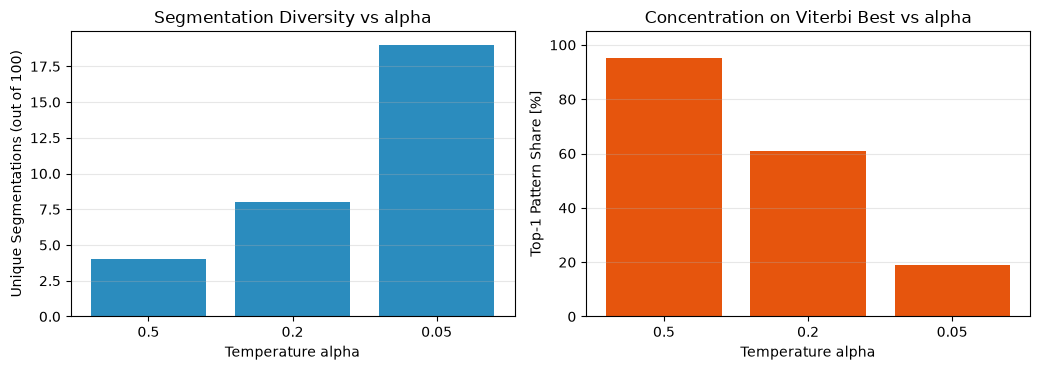

In [6]:
from collections import Counter
import matplotlib.pyplot as plt

rich_corpus = [
    "自然言語処理の教科書を読みました。",
    "自然言語と自然言語処理の基礎を学びます。",
    "言語処理と形態素解析の手法を比較します。",
    "東京都立大学の研究室で自然言語処理を研究しています。",
    "東京都の都立大学で研究開発を進めます。",
    "機械翻訳と文書要約は系列変換タスクです。",
    "深層学習と事前学習モデルが広く使われています。",
    "深層学習モデルの事前学習とファインチューニングを行います。",
    "研究開発センターでデータ拡張の研究開発を進める。",
    "データ拡張とサブワード正則化により未知語に強くなります。",
] * 25

with tempfile.TemporaryDirectory() as tmpdir:
    cpath = Path(tmpdir) / "rich_corpus.txt"
    mprefix = str(Path(tmpdir) / "sp_unigram")
    cpath.write_text("\n".join(rich_corpus), encoding="utf-8")

    # 複合語の複数候補を見やすくするため byte_fallback=False で小規模語彙 (180) を学習
    spm.SentencePieceTrainer.train(
        input=str(cpath),
        model_prefix=mprefix,
        vocab_size=180,
        model_type="unigram",
        character_coverage=1.0,
        byte_fallback=False,
        hard_vocab_limit=False,
        minloglevel=2,
        bos_id=-1,
        eos_id=-1,
    )
    sp_uni = spm.SentencePieceProcessor(model_file=f"{mprefix}.model")

target_sent = "東京都立大学で自然言語処理の研究開発を進める。"
print("Viterbi 最尤分割:", sp_uni.encode_as_pieces(target_sent))
print("\n=== nbest_encode_as_pieces(nbest_size=5) による上位 5 候補 ===")
for rank, pieces in enumerate(sp_uni.nbest_encode_as_pieces(target_sent, nbest_size=5), 1):
    print(f"  {rank}位 ({len(pieces):2d}ピース): {pieces}")

spm.set_random_generator_seed(42)
alpha_stats = []
sample_examples = {}
for alpha in [0.5, 0.2, 0.05]:
    samples = [
        tuple(sp_uni.encode(target_sent, out_type=str, enable_sampling=True, alpha=alpha, nbest_size=-1))
        for _ in range(100)
    ]
    cnt = Counter(samples)
    top_seq, top_cnt = cnt.most_common(1)[0]
    alpha_stats.append({
        "alpha": alpha,
        "ユニーク分割パターン数 (100回中)": len(cnt),
        "最頻パターンの割合 [%]": top_cnt,
        "平均サブワード長": round(sum(len(s) for s in samples) / len(samples), 2),
        "最小〜最大ピース数": f"{min(len(s) for s in samples)}〜{max(len(s) for s in samples)}",
    })
    sample_examples[alpha] = cnt.most_common(4)

stats_df = pd.DataFrame(alpha_stats)
print("\n=== 平滑化係数 alpha ごとのサンプリング統計（各 100 回） ===")
display(stats_df)

for alpha in [0.2, 0.05]:
    print(f"\n[alpha={alpha}] 出現上位 4 パターン:")
    for pat, c in sample_examples[alpha]:
        print(f"  {c:2d}回: {list(pat)}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
a_labels = [str(a) for a in stats_df["alpha"]]
axes[0].bar(a_labels, stats_df["ユニーク分割パターン数 (100回中)"], color="#2b8cbe")
axes[0].set_xlabel("Temperature alpha")
axes[0].set_ylabel("Unique Segmentations (out of 100)")
axes[0].set_title("Segmentation Diversity vs alpha")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(a_labels, stats_df["最頻パターンの割合 [%]"], color="#e6550d")
axes[1].set_xlabel("Temperature alpha")
axes[1].set_ylabel("Top-1 Pattern Share [%]")
axes[1].set_ylim(0, 105)
axes[1].set_title("Concentration on Viterbi Best vs alpha")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 第 4 節の観察

- **複数分割候補の保持**: 「自然言語処理の」「研究」といった長い複合語ピースを選ぶ候補（1〜2 位）だけでなく、「自然言語 / 処 / 理 / の研究」（3 位）や「▁ / 東 / 京 / 都 / ...」（5 位）のように細かく分割する候補にも確率が割り当てられています。
- **温度 `alpha` の効果**: `alpha=0.5` では最尤分割への集中率が `95%`（4 パターン、平均長 `14.08`）と決定論的に近いのに対し、`alpha=0.2` では 8 パターン（最頻 `61%`、平均長 `14.85`）、`alpha=0.05` では 19 パターン（最頻 `19%`、平均長 `17.58`）の多様な分割がサンプリングされます。訓練時にこうして複数の分割を見せておくことで、推論時に未知の複合語へ細かい分割が出現しても意味を安定して捉えやすくなります (Kudo, ACL 2018)。

### 次の演習への案内

- **3-2 後半（単語ラティス・仮名漢字変換・CRF vs MEMM・Pointwise 予測）**: [単語ラティス・仮名漢字変換・CRF vs MEMM・Pointwise 予測](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch3_viterbi_crf.ipynb)
- **3-1 固有表現認識（旧第 4〜5 節の BIO タグ・`sklearn-crfsuite` による素性テンプレートと CRF 実験を移設統合）**: [固有表現認識の基礎（ガゼッティア・BIO タグ・素性テンプレートと CRF・サブワード整合）](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch3_ner_gazetteer_subword.ipynb)